# Lab 1B: Feature Detection
**Course:** 0135326 - Computer Vision
**Instructor:** Dr. Akram Fatayer
---

## 1. Introduction & Learning Objectives

Welcome to the second part of Lab 1! In this lab, we will build upon the image processing fundamentals from Lab 1A and explore how to detect meaningful **features** in images. Features like edges and corners are the building blocks for many higher-level computer vision tasks like object recognition and tracking.

By the end of this lab, you will be able to:

1.  Understand and compute **image gradients** using the Sobel operator.
2.  Apply the **Canny edge detector** to find sharp edges in an image.
3.  Detect corners using the **Harris Corner Detector**.
4.  Appreciate the concept of **feature descriptors** and their importance.

## 2. Setup

As before, we will import our standard libraries. We will also download a new sample image that has clear geometric shapes, which is excellent for feature detection.

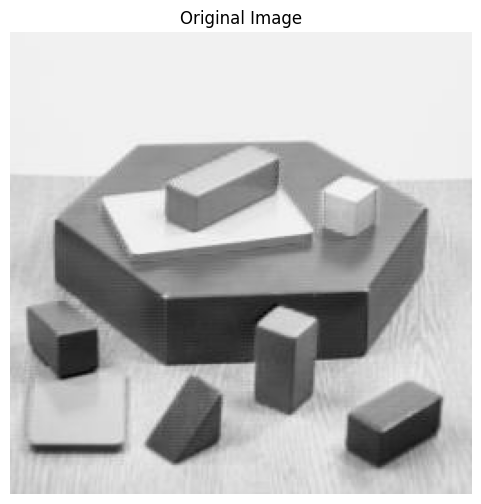

In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

%matplotlib inline

# Download a suitable image for feature detection
!wget -q https://raw.githubusercontent.com/akramfatayer/zuj-cv/main/images/blox.jpg -O blox.jpg

# Load the image and convert to grayscale
image_bgr = cv2.imread('blox.jpg')
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
image_gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

# Display the original image
plt.figure(figsize=(6,6))
plt.imshow(image_rgb)
plt.title('Original Image')
plt.axis('off')
plt.show()

## 3. Edge Detection with Canny

Edges are one of the most important features in an image. They represent boundaries of objects and changes in texture. The **Canny edge detector** is a multi-stage algorithm that is very effective at finding edges.

It takes two main parameters: `threshold1` and `threshold2`. These are the lower and upper thresholds for the hysteresis procedure. Any gradient values larger than `threshold2` are considered sure-edges, and any between `threshold1` and `threshold2` are considered edges only if they are connected to a sure-edge.

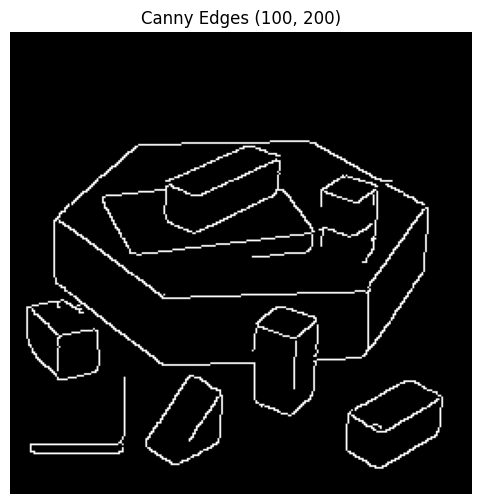

In [3]:
# Apply Canny edge detection
edges = cv2.Canny(image_gray, threshold1=100, threshold2=200)

# Display the result
plt.figure(figsize=(6,6))
plt.imshow(edges, cmap='gray')
plt.title('Canny Edges (100, 200)')
plt.axis('off')
plt.show()

### Exercise 1: Experiment with Canny Thresholds

In the code block below, apply the Canny edge detector with two different sets of thresholds:
1. A **low** threshold pair (e.g., 50, 100)
2. A **high** threshold pair (e.g., 150, 250)

Display the results side-by-side. What is the effect of changing the thresholds?

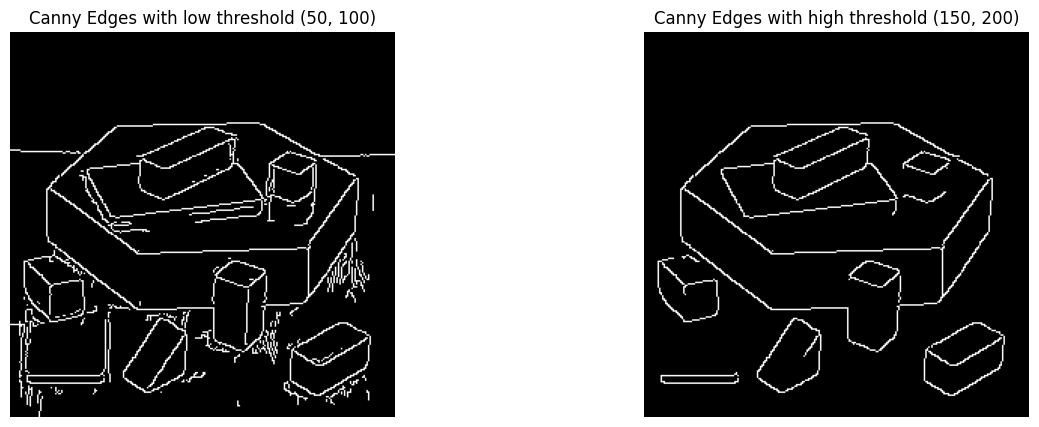

In [4]:
# --- YOUR CODE HERE ---
# 1. Apply Canny with low thresholds (50, 100)
edges_low = cv2.Canny(image_gray, threshold1=50, threshold2=100) # Replace this

# 2. Apply Canny with high thresholds (150, 250)
edges_high = cv2.Canny(image_gray, threshold1=150, threshold2=250) # Replace this

# 3. Display the results in a 1x2 subplot
plt.figure(figsize=(15, 5))

plt.subplot(1,2,1)
plt.imshow(edges_low, cmap='gray')
plt.title('Canny Edges with low threshold (50, 100)')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(edges_high, cmap='gray')
plt.title('Canny Edges with high threshold (150, 200)')
plt.axis('off')
plt.show()
# --- END OF YOUR CODE ---

## 4. Corner Detection with Harris

Corners are another important type of feature. They are points where the intensity changes significantly in multiple directions. The **Harris Corner Detector** is a classic algorithm for finding these points.

The function `cv2.cornerHarris()` takes the grayscale image, a block size (the size of the neighborhood considered), a ksize (aperture parameter for the Sobel operator), and a free parameter `k`.

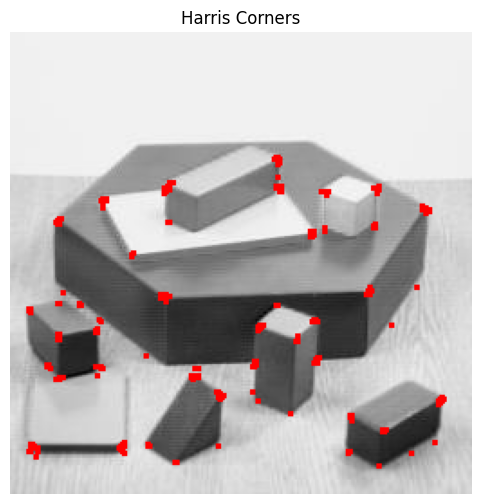

In [5]:
# The Harris detector works on float32 images
gray_float = np.float32(image_gray)

# Apply Harris Corner Detector
# cv2.cornerHarris(image, blockSize, ksize, k)
harris_corners = cv2.cornerHarris(gray_float, 2, 3, 0.04)

# The result is a grayscale image where bright pixels are corners.
# We can dilate it to make the corners more visible.
harris_corners = cv2.dilate(harris_corners, None)

# To display them on the original image, we can set a threshold.
image_with_corners = image_rgb.copy()
# Mark the corners in red where the harris_corners value is > 1% of its max value
image_with_corners[harris_corners > 0.01 * harris_corners.max()] = [255, 0, 0] # Red

# Display the result
plt.figure(figsize=(6,6))
plt.imshow(image_with_corners)
plt.title('Harris Corners')
plt.axis('off')
plt.show()

### Exercise 2: Tune the Harris Detector

The threshold `0.01` in the visualization code (`harris_corners > 0.01 * harris_corners.max()`) is arbitrary. A lower threshold will detect more (and weaker) corners, while a higher threshold will detect only the strongest ones.

In the code block below, try two different thresholds and observe the results:
1. A **low** threshold (e.g., `0.001`)
2. A **high** threshold (e.g., `0.1`)

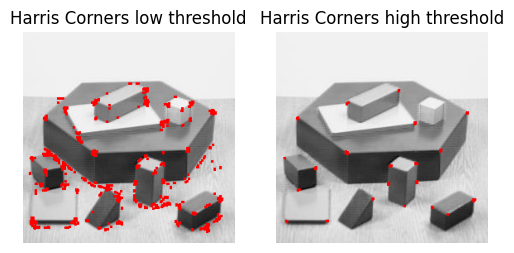

In [6]:
# --- YOUR CODE HERE ---
# 1. Create a copy of the original image for the low threshold result
image_corners_low = image_rgb.copy()
# Mark corners using a low threshold (0.001)
image_corners_low[harris_corners > 0.001 * harris_corners.max()] = [255, 0, 0]
# 2. Create another copy for the high threshold result
image_corners_high = image_rgb.copy()
# Mark corners using a high threshold (0.1)
image_corners_high[harris_corners > 0.1 * harris_corners.max()] = [255, 0, 0]
# 3. Display the two results in a 1x2 subplot
plt.figure(figsize=(6,6))

plt.subplot(1,2,1)
plt.imshow(image_corners_low)
plt.title('Harris Corners low threshold')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(image_corners_high)
plt.title('Harris Corners high threshold')
plt.axis('off')

plt.show()

# --- END OF YOUR CODE ---

Great work! You have now implemented two of the most fundamental feature detectors in computer vision. These simple features are the foundation for more complex algorithms like SIFT, SURF, and modern deep learning-based feature extractors.


"""
## 6. Feature Descriptors & Matching with SIFT (Real Images)

Corners/edges tell us *where* interesting structure is, but for matching we need a
descriptor that tells us *what* the neighborhood looks like.

We will:
1) Load two related real images: `box.png` and `box_in_scene.png`.
2) Detect keypoints + compute descriptors (SIFT).
3) Match descriptors using BFMatcher + Lowe's ratio test.
4) (Optional) Estimate homography with RANSAC and draw the detected object in the scene.
"""

In [7]:
import os
import urllib.request

def download_if_missing(url, filename):
    if not os.path.exists(filename):
        urllib.request.urlretrieve(url, filename)

# OpenCV sample images (4.x branch)
url_box = "https://raw.githubusercontent.com/akramfatayer/zuj-cv/main/images/box.png"
url_scene = "https://raw.githubusercontent.com/akramfatayer/zuj-cv/main/images/box_in_scene.png"

download_if_missing(url_box, "box.png")
download_if_missing(url_scene, "box_in_scene.png")

Method: SIFT
Keypoints: img1=604, img2=969
Good matches (ratio=0.75): 80


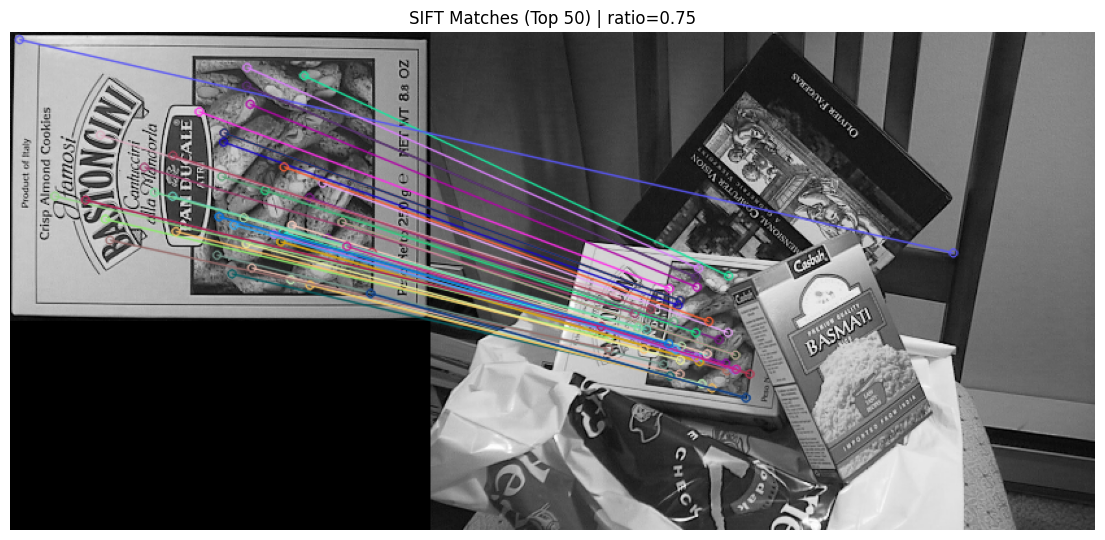

In [8]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

# 1) Load images (grayscale for SIFT, RGB for display)
img1 = cv2.imread("box.png", cv2.IMREAD_GRAYSCALE)          # query
img2 = cv2.imread("box_in_scene.png", cv2.IMREAD_GRAYSCALE) # train

if img1 is None or img2 is None:
    raise FileNotFoundError("Could not load box.png or box_in_scene.png. Check download step.")

img1_rgb = cv2.cvtColor(img1, cv2.COLOR_GRAY2RGB)
img2_rgb = cv2.cvtColor(img2, cv2.COLOR_GRAY2RGB)

# 2) Create SIFT (fallback to ORB if SIFT isn't available in this OpenCV build)
# SIFT is available as cv2.SIFT_create() in modern OpenCV; older builds may not include it. [5](https://stackoverflow.com/questions/60065707/cant-use-sift-in-python-opencv-v4-20)[6](https://forum.opencv.org/t/payment-for-academic-and-commercial-use-of-the-sift-algorithm/20284)
try:
    detector = cv2.SIFT_create()
    norm_type = cv2.NORM_L2
    method_name = "SIFT"
except AttributeError:
    detector = cv2.ORB_create(nfeatures=1500)
    norm_type = cv2.NORM_HAMMING
    method_name = "ORB (fallback)"

# 3) Detect keypoints + descriptors
kp1, des1 = detector.detectAndCompute(img1, None)
kp2, des2 = detector.detectAndCompute(img2, None)

print(f"Method: {method_name}")
print(f"Keypoints: img1={len(kp1)}, img2={len(kp2)}")

# 4) Match with BFMatcher + Lowe’s ratio test (knnMatch)
# BFMatcher + ratio test workflow is standard in OpenCV tutorials. [2](https://docs.opencv.org/4.x/dc/dc3/tutorial_py_matcher.html)
bf = cv2.BFMatcher(norm_type, crossCheck=False)
matches_knn = bf.knnMatch(des1, des2, k=2)

ratio = 0.75  # TODO: Try 0.6, 0.75, 0.9 and observe match quality vs quantity.
good = []
for m, n in matches_knn:
    if m.distance < ratio * n.distance:
        good.append(m)

print(f"Good matches (ratio={ratio}): {len(good)}")

# 5) Visualize a subset (for readability)
good_sorted = sorted(good, key=lambda x: x.distance)
top_k = 50  # TODO: try 20, 50, 100
vis_matches = cv2.drawMatches(
    img1_rgb, kp1,
    img2_rgb, kp2,
    good_sorted[:top_k], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(14, 7))
plt.imshow(vis_matches)
plt.title(f"{method_name} Matches (Top {min(top_k, len(good_sorted))}) | ratio={ratio}")
plt.axis("off")
plt.show()

## 5. Conclusion & Submission



### Deliverables
1.  **Completed Notebook:** Ensure all your code cells for the exercises are filled in and run without errors.
2.  **Brief Reflection:** In the markdown cell below, answer the following: What is the main difference between an edge and a corner? Why might one be more useful than the other for a task like object tracking?
3. How does changing ratio affect precision vs recall in matches?
4. Why can’t Harris corners alone solve this task without descriptors? (Hint: “where” vs “what”)

### Reflection

*--- Write your reflection here ---*